# 05. Risk Scoring Engine & Tier Stratification
**UPI Fraud Detection and Risk Analytics**

### Objectives:
1. Develop a multi-dimensional rule-based Risk Scoring Engine (0 to 100 continuous score).
2. Engineer granular sub-scores across 5 dimensions:
   - Financial Magnitude / Amount Anomaly Score (30 pts)
   - Bank Latency / Response Time Score (25 pts)
   - Transaction Type & Channel Risk Weight (20 pts)
   - Transaction Status & Failure History Penalty (15 pts)
   - Temporal / Weekend Risk Penalty (10 pts)
3. Stratify transactions into Risk Tiers: **Low Risk** (0-30), **Medium Risk** (31-70), **High Risk** (71-100).
4. Validate risk score performance against actual `Fraud_Label` using ROC-AUC, PR-AUC, Precision, and Recall.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, confusion_matrix, classification_report

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
%matplotlib inline


## 1. Load Processed Dataset

In [2]:
data_path = r"C:\UPI Data\UPI_Transactions_Cleaned.csv"
if not os.path.exists(data_path):
    data_path = r"C:\UPI Data\UPI_Transactions_Cleaned.csv"

df = pd.read_csv(data_path)
print(f'Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()


Dataset Loaded: 10000 rows, 24 columns


,Transaction_ID,Transaction_Date,Customer_ID,City,State,Sender_Bank,Receiver_Bank,UPI_App,Transaction_Type,Payment_Method,Amount,Transaction_Status,Failure_Reason,Processing_Time_sec,Bank_Response_Time_ms,Fraud_Label,Year,Month,Month_Name,Day,Day_of_Week,Day_of_Week_Num,Is_Weekend,Quarter
0,TXN100000,2025-11-24,CUST09196,Bengaluru,Karnataka,SBI,Kotak Mahindra Bank,PhonePe,Online Purchase,Mobile Number,2014.53,Success,Not Applicable,4.83,801,0,2025,11,Nov,24,Monday,0,0,4
1,TXN100001,2025-04-23,CUST01520,Ahmedabad,Gujarat,Yes Bank,Kotak Mahindra Bank,BHIM,P2P,UPI ID,1359.97,Success,Not Applicable,1.58,751,0,2025,4,Apr,23,Wednesday,2,0,2
2,TXN100002,2025-06-26,CUST09460,Lucknow,Uttar Pradesh,Kotak Mahindra Bank,SBI,PhonePe,P2P,UPI,8199.06,Success,Not Applicable,3.03,816,0,2025,6,Jun,26,Thursday,3,0,2
3,TXN100003,2025-12-05,CUST05821,Mumbai,Maharashtra,Kotak Mahindra Bank,HDFC Bank,PhonePe,Bill Payment,UPI,2240.06,Success,Not Applicable,3.58,345,0,2025,12,Dec,5,Friday,4,0,4
4,TXN100004,2025-11-08,CUST00526,Kochi,Kerala,ICICI Bank,Union Bank,Paytm,Recharge,UPI ID,320.36,Success,Not Applicable,4.48,888,0,2025,11,Nov,8,Saturday,5,1,4


## 2. Sub-Score Engineering (Risk Components)

In [3]:
# 1. Amount Anomaly Score (0 - 30 pts)
# Quantile-based mapping for transaction amount
amount_q95 = df['Amount'].quantile(0.95)
amount_q75 = df['Amount'].quantile(0.75)
amount_q50 = df['Amount'].quantile(0.50)

def calc_amount_score(amt):
    if amt > amount_q95:
        return 30
    elif amt > amount_q75:
        return 20
    elif amt > amount_q50:
        return 10
    else:
        return 5

df['Score_Amount'] = df['Amount'].apply(calc_amount_score)

# 2. Bank Latency Score (0 - 25 pts)
resp_q90 = df['Bank_Response_Time_ms'].quantile(0.90)
resp_q75 = df['Bank_Response_Time_ms'].quantile(0.75)

def calc_latency_score(latency):
    if latency > resp_q90:
        return 25
    elif latency > resp_q75:
        return 15
    else:
        return 5

df['Score_Latency'] = df['Bank_Response_Time_ms'].apply(calc_latency_score)

# 3. Channel & Method Risk Score (0 - 20 pts)
method_weights = {
    'QR Code': 18,
    'UPI ID': 15,
    'Mobile Number': 12,
    'Bank Account': 10,
    'UPI': 10
}
df['Score_Channel'] = df['Payment_Method'].map(lambda x: method_weights.get(x, 10))

# 4. Transaction Failure Score (0 - 15 pts)
def calc_failure_score(status, reason):
    if status == 'Failed':
        if reason in ['Bank Server Error', 'Daily Limit Exceeded', 'Transaction Timeout']:
            return 15
        return 10
    elif status == 'Pending':
        return 8
    return 0

df['Score_Failure'] = df.apply(lambda row: calc_failure_score(row['Transaction_Status'], row['Failure_Reason']), axis=1)

# 5. Temporal Weekend Penalty (0 - 10 pts)
df['Score_Temporal'] = df['Is_Weekend'].apply(lambda x: 10 if x == 1 else 3)

df[['Score_Amount', 'Score_Latency', 'Score_Channel', 'Score_Failure', 'Score_Temporal']].head()


,Score_Amount,Score_Latency,Score_Channel,Score_Failure,Score_Temporal
0,20,5,12,0,3
1,10,5,15,0,3
2,30,5,10,0,3
3,20,5,10,0,3
4,5,15,15,0,10


## 3. Composite Risk Score & Risk Tier Stratification

In [4]:
df['Composite_Risk_Score'] = (
    df['Score_Amount'] + 
    df['Score_Latency'] + 
    df['Score_Channel'] + 
    df['Score_Failure'] + 
    df['Score_Temporal']
)

# Normalize/Cap score to 0 - 100
df['Risk_Score'] = df['Composite_Risk_Score'].clip(0, 100)

def assign_risk_tier(score):
    if score >= 70:
        return 'High Risk'
    elif score >= 40:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df['Risk_Tier'] = df['Risk_Score'].apply(assign_risk_tier)

tier_summary = df.groupby('Risk_Tier').agg(
    Txn_Count=('Fraud_Label', 'count'),
    Fraud_Count=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
).reset_index()
tier_summary['Fraud_Rate_Pct'] = (tier_summary['Fraud_Rate_Mean'] * 100).round(2)
tier_summary['Share_of_Total_Fraud'] = ((tier_summary['Fraud_Count'] / df['Fraud_Label'].sum()) * 100).round(2)

print('Risk Tier Stratification Matrix:')
display(tier_summary)


Risk Tier Stratification Matrix:


,Risk_Tier,Txn_Count,Fraud_Count,Fraud_Rate_Mean,Fraud_Rate_Pct,Share_of_Total_Fraud
0,High Risk,103,1,0.009709,0.97,1.01
1,Low Risk,6050,41,0.006777,0.68,41.41
2,Medium Risk,3847,57,0.014817,1.48,57.58


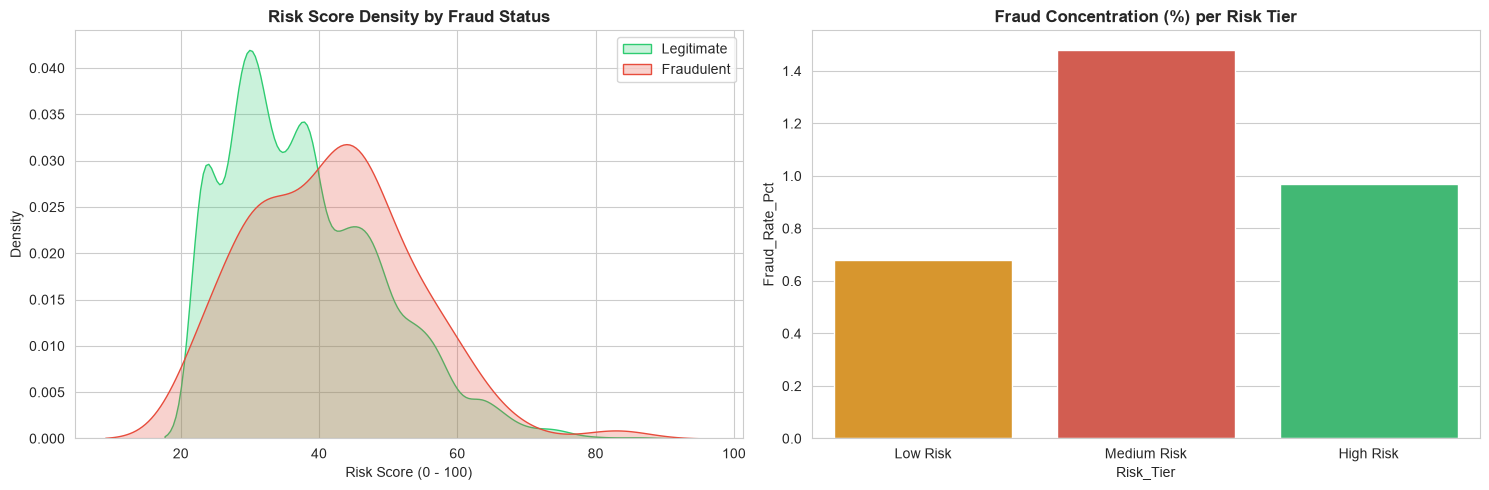

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Score Distribution by Fraud Status
for label, color, name in [(0, '#2ecc71', 'Legitimate'), (1, '#e74c3c', 'Fraudulent')]:
    sns.kdeplot(df[df['Fraud_Label'] == label]['Risk_Score'], ax=axes[0], color=color, label=name, fill=True)
axes[0].set_title('Risk Score Density by Fraud Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Risk Score (0 - 100)')
axes[0].legend()

# Fraud Concentration by Tier
sns.barplot(data=tier_summary, x='Risk_Tier', y='Fraud_Rate_Pct', hue='Risk_Tier', ax=axes[1], order=['Low Risk', 'Medium Risk', 'High Risk'], palette=['#2ecc71', '#f39c12', '#e74c3c'], legend=False)
axes[1].set_title('Fraud Concentration (%) per Risk Tier', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Score Performance & Model Calibration

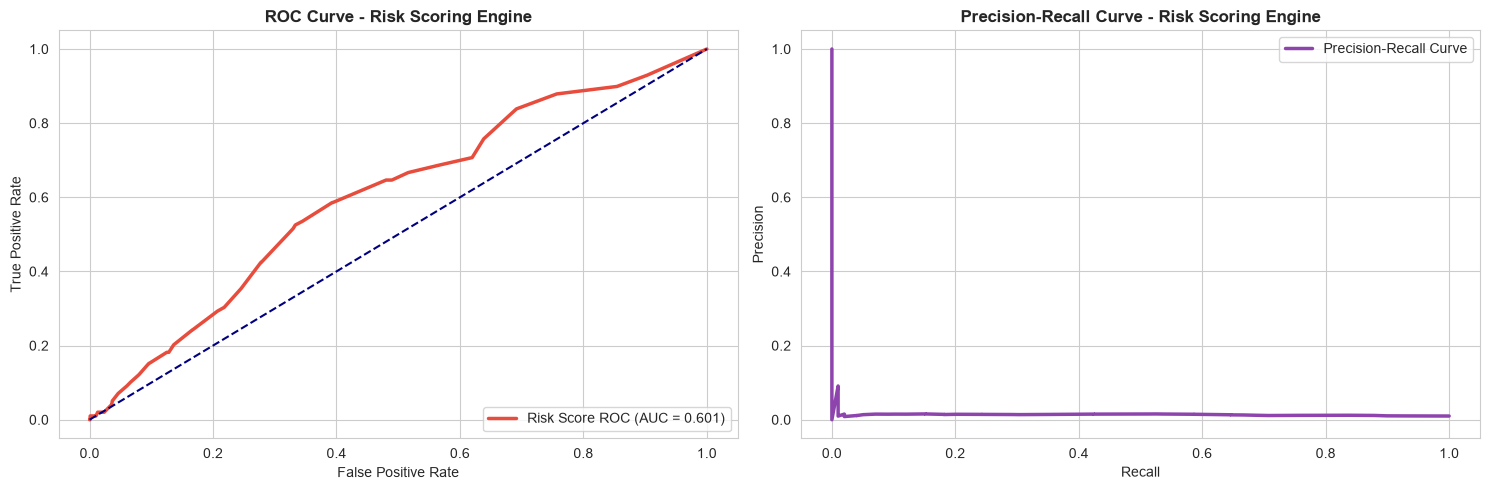

Risk Scoring Engine ROC-AUC Score: 0.6007


In [7]:
fpr, tpr, thresholds = roc_curve(df['Fraud_Label'], df['Risk_Score'])
roc_auc = auc(fpr, tpr)

precision, recall, pr_thresholds = precision_recall_curve(df['Fraud_Label'], df['Risk_Score'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color='#e74c3c', lw=2.5, label=f'Risk Score ROC (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve - Risk Scoring Engine', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right')

# Precision-Recall Curve
axes[1].plot(recall, precision, color='#8e44ad', lw=2.5, label='Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve - Risk Scoring Engine', fontsize=12, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'Risk Scoring Engine ROC-AUC Score: {roc_auc:.4f}')


## 5. High-Risk Threshold Classification Performance

In [8]:
# Evaluate classification binary decision: Risk_Score >= 70 as Fraud prediction
pred_high_risk = (df['Risk_Score'] >= 70).astype(int)

cm = confusion_matrix(df['Fraud_Label'], pred_high_risk)
print('Confusion Matrix (Threshold Score >= 70):')
print(cm)

print('\nClassification Report:')
print(classification_report(df['Fraud_Label'], pred_high_risk, target_names=['Legitimate', 'High-Risk Fraud']))


Confusion Matrix (Threshold Score >= 70):
[[9799  102]
 [  98    1]]

Classification Report:
                 precision    recall  f1-score   support

     Legitimate       0.99      0.99      0.99      9901
High-Risk Fraud       0.01      0.01      0.01        99

       accuracy                           0.98     10000
      macro avg       0.50      0.50      0.50     10000
   weighted avg       0.98      0.98      0.98     10000

